# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [2]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv('../data/co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


ModuleNotFoundError: No module named 'plotly'

In [ ]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: ['United States' 'China' 'India' 'Germany' 'United Kingdom' 'France'
 'Brazil' 'Japan' 'Canada' 'Australia' 'South Korea' 'Russia'
 'South Africa' 'Mexico' 'Indonesia']

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


---
## Task — Multi-Series Line Chart with Highlight

**What to build:** A line chart showing CO2 emissions over time for **all Asian countries** in the dataset, with one country highlighted.

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country and its story

In [ ]:
%pip install pandas matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 4.7 MB/s  0:00:02eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 5.4 MB/s  0:00:01 eta 0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 8.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 5.3 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 8.8 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [matplotlib]9 [matplotlib]

[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully!


In [ ]:
import os

print("Current folder:", os.getcwd())
print("Files in this folder:", os.listdir())

Current folder: /Users/manasa22/Desktop/dv/data-viz-class-material-w2026/week03
Files in this folder: ['lecture03_exercise.ipynb', 'lecture03_notes.ipynb']


In [ ]:
import os
# Check the main project folder
project_folder = "/Users/manasa22/Desktop/dv/data-viz-class-material-w2026"
for root, dirs, files in os.walk(project_folder):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

/Users/manasa22/Desktop/dv/data-viz-class-material-w2026/data/global_energy_mix.csv
/Users/manasa22/Desktop/dv/data-viz-class-material-w2026/data/netflix_catalogue.csv
/Users/manasa22/Desktop/dv/data-viz-class-material-w2026/data/co2_emissions.csv
/Users/manasa22/Desktop/dv/data-viz-class-material-w2026/data/world_development.csv
/Users/manasa22/Desktop/dv/data-viz-class-material-w2026/data/airbnb_london.csv
/Users/manasa22/Desktop/dv/data-viz-class-material-w2026/data/world_happiness_2023.csv
/Users/manasa22/Desktop/dv/data-viz-class-material-w2026/data/gapminder.csv


In [ ]:
import os

search_folder = "/Users/manasa22/Desktop"

for root, dirs, files in os.walk(search_folder):
    if "co2_emissions.csv" in files:
        print("File found!")
        print(os.path.join(root, "co2_emissions.csv"))

File found!
/Users/manasa22/Desktop/dv/data-viz-class-material-w2026-main/data/co2_emissions.csv
File found!
/Users/manasa22/Desktop/dv/data-viz-class-material-w2026/data/co2_emissions.csv


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    "/Users/manasa22/Desktop/dv/data-viz-class-material-w2026/data/co2_emissions.csv"
)

print(df.head())
print(df.columns.tolist())

         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12
['Country', 'Region', 'Year', 'CO2_Mt', 'CO2_per_capita']


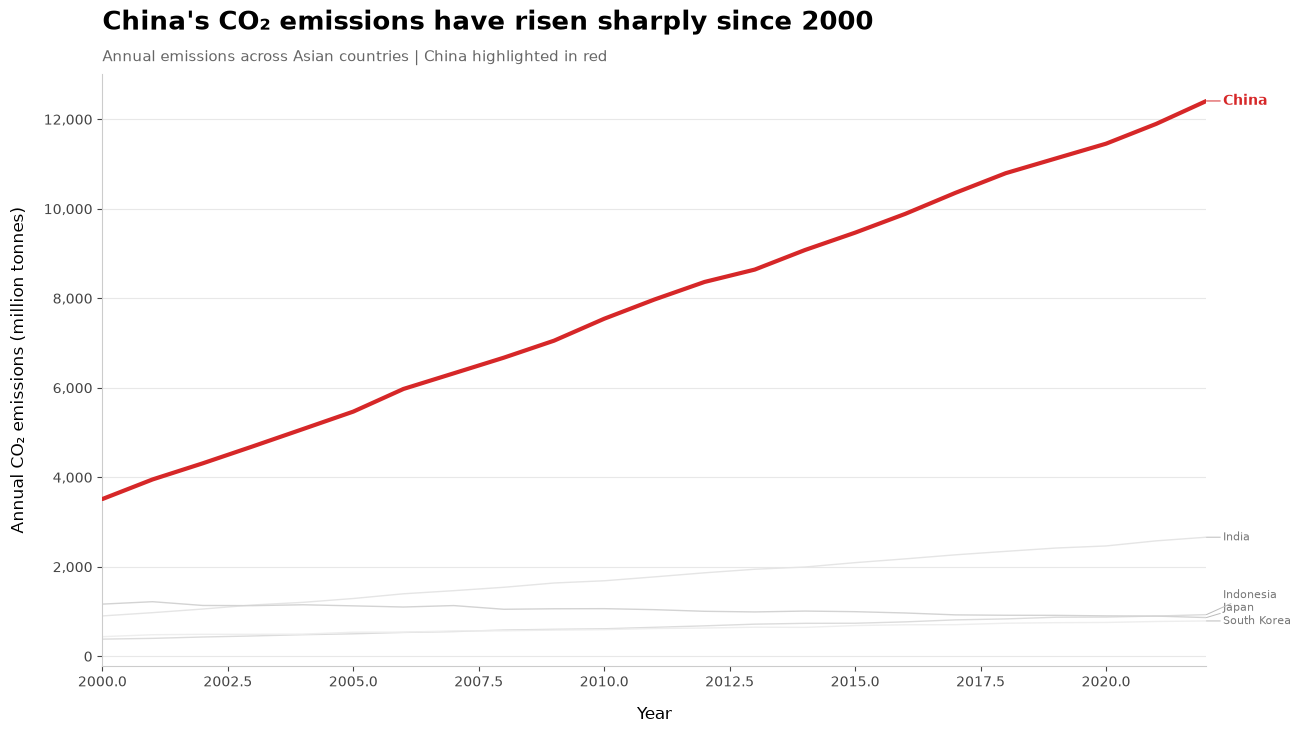

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# --------------------------------------------------
# 1. Prepare the data
# --------------------------------------------------

country_col = "Country"
region_col = "Region"
year_col = "Year"
emissions_col = "CO2_Mt"

asia = df[
    df[region_col].astype(str).str.strip().str.lower() == "asia"
].copy()

asia[year_col] = pd.to_numeric(asia[year_col], errors="coerce")
asia[emissions_col] = pd.to_numeric(
    asia[emissions_col], errors="coerce"
)

asia = asia.dropna(
    subset=[country_col, year_col, emissions_col]
)

asia = (
    asia.groupby([country_col, year_col], as_index=False)
    [emissions_col]
    .sum()
    .sort_values(year_col)
)

# Remove countries without enough data to draw a line
country_counts = asia.groupby(country_col)[year_col].nunique()
asia = asia[
    asia[country_col].isin(country_counts[country_counts >= 2].index)
].copy()

highlight_country = "China"

highlight_data = asia[
    asia[country_col].str.strip().str.lower()
    == highlight_country.lower()
].sort_values(year_col)

if highlight_data.empty:
    raise ValueError("China was not found in the Asian data.")

# --------------------------------------------------
# 2. Create a wide, polished chart
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(16, 8))

# Different grey shades for background countries
grey_shades = ["#EEEEEE", "#E5E5E5", "#DCDCDC", "#D3D3D3"]

# Plot all other countries first
for i, (country, data) in enumerate(asia.groupby(country_col)):
    if country.strip().lower() == highlight_country.lower():
        continue

    data = data.sort_values(year_col)

    ax.plot(
        data[year_col],
        data[emissions_col],
        color=grey_shades[i % len(grey_shades)],
        linewidth=1.0,
        zorder=1
    )

# Plot China on top
ax.plot(
    highlight_data[year_col],
    highlight_data[emissions_col],
    color="#D62728",
    linewidth=3,
    solid_capstyle="round",
    zorder=5
)

# --------------------------------------------------
# 3. Label every country at the right end
# --------------------------------------------------

# Store the final value of each country's line
endpoints = []

for country, data in asia.groupby(country_col):
    data = data.sort_values(year_col)
    last = data.iloc[-1]

    endpoints.append({
        "country": country,
        "year": last[year_col],
        "value": last[emissions_col]
    })

# Sort endpoints by emission value
endpoints = sorted(endpoints, key=lambda item: item["value"])

# Spread nearby labels apart vertically to reduce overlap
if endpoints:
    min_y = min(item["value"] for item in endpoints)
    max_y = max(item["value"] for item in endpoints)

    # Minimum separation between label positions
    min_gap = max((max_y - min_y) * 0.025, 80)

    label_positions = []

    for item in endpoints:
        label_y = item["value"]

        if label_positions:
            label_y = max(label_y, label_positions[-1] + min_gap)

        label_positions.append(label_y)

    # Draw connector lines and labels
    for item, label_y in zip(endpoints, label_positions):
        is_highlight = (
            item["country"].strip().lower()
            == highlight_country.lower()
        )

        label_color = "#D62728" if is_highlight else "#777777"
        label_weight = "bold" if is_highlight else "normal"
        label_size = 10 if is_highlight else 8

        ax.annotate(
            item["country"],
            xy=(item["year"], item["value"]),
            xytext=(12, label_y),
            textcoords=("offset points", "data"),
            ha="left",
            va="center",
            fontsize=label_size,
            fontweight=label_weight,
            color=label_color,
            arrowprops=dict(
                arrowstyle="-",
                color=label_color if is_highlight else "#BBBBBB",
                linewidth=0.7,
                shrinkA=0,
                shrinkB=0
            ),
            annotation_clip=False,
            zorder=6 if is_highlight else 4
        )

# --------------------------------------------------
# 4. Title and subtitle
# --------------------------------------------------

ax.set_title(
    "China's CO₂ emissions have risen sharply since 2000",
    loc="left",
    fontsize=19,
    fontweight="bold",
    pad=32
)

ax.text(
    0,
    1.015,
    "Annual emissions across Asian countries | China highlighted in red",
    transform=ax.transAxes,
    fontsize=11,
    color="#666666",
    va="bottom"
)

# --------------------------------------------------
# 5. Axis formatting and clean design
# --------------------------------------------------

ax.set_xlabel("Year", fontsize=12, labelpad=12)

ax.set_ylabel(
    "Annual CO₂ emissions (million tonnes)",
    fontsize=12,
    labelpad=12
)

ax.yaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:,.0f}")
)

# Remove top and right borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("#CCCCCC")
ax.spines["bottom"].set_color("#CCCCCC")

ax.tick_params(axis="both", labelsize=10, colors="#444444")

# Horizontal gridlines only
ax.grid(
    axis="y",
    color="#E8E8E8",
    linewidth=0.8
)

ax.set_axisbelow(True)

# Keep the x-axis ending at the last observed year;
# labels sit outside the plot area on the right.
ax.set_xlim(
    asia[year_col].min(),
    asia[year_col].max()
)

# Reserve room on the right for direct country labels
fig.subplots_adjust(
    left=0.09,
    right=0.78,
    top=0.86,
    bottom=0.12
)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

plt.show()

In [5]:
import pandas as pd
import plotly.graph_objects as go

# --------------------------------------------------
# 1. Prepare the data
# --------------------------------------------------

country_col = "Country"
region_col = "Region"
year_col = "Year"
emissions_col = "CO2_Mt"

asia = df[
    df[region_col].astype(str).str.strip().str.lower() == "asia"
].copy()

asia[year_col] = pd.to_numeric(asia[year_col], errors="coerce")

asia[emissions_col] = pd.to_numeric(
    asia[emissions_col], errors="coerce"
)

asia = asia.dropna(
    subset=[country_col, year_col, emissions_col]
)

asia[country_col] = asia[country_col].astype(str).str.strip()

asia = (
    asia.groupby([country_col, year_col], as_index=False)
    [emissions_col]
    .sum()
    .sort_values(year_col)
)

# Remove countries with fewer than two years of data
country_counts = asia.groupby(country_col)[year_col].nunique()

asia = asia[
    asia[country_col].isin(
        country_counts[country_counts >= 2].index
    )
].copy()

highlight_country = "China"

highlight_data = asia[
    asia[country_col].str.lower() == highlight_country.lower()
].sort_values(year_col)

if highlight_data.empty:
    raise ValueError("China was not found in the Asian data.")

# --------------------------------------------------
# 2. Create the interactive Plotly chart
# --------------------------------------------------

fig = go.Figure()

# Light grey shades for background countries
grey_shades = [
    "#D9D9D9",
    "#CFCFCF",
    "#E0E0E0",
    "#D5D5D5",
    "#E5E5E5"
]

# Plot every country except China
other_countries = asia[
    asia[country_col].str.lower() != highlight_country.lower()
]

for i, (country, data) in enumerate(
    other_countries.groupby(country_col, sort=True)
):
    data = data.sort_values(year_col)

    fig.add_trace(
        go.Scatter(
            x=data[year_col],
            y=data[emissions_col],
            mode="lines",
            name=country,
            line=dict(
                color=grey_shades[i % len(grey_shades)],
                width=1.3
            ),
            customdata=[
                [country, year, emissions]
                for year, emissions in zip(
                    data[year_col], data[emissions_col]
                )
            ],
            hovertemplate=(
                "<b>%{customdata[0]}</b><br>"
                "Year: %{customdata[1]:.0f}<br>"
                "CO₂ emissions: %{customdata[2]:,.2f} Mt"
                "<extra></extra>"
            ),
            showlegend=False
        )
    )

# --------------------------------------------------
# 3. Highlight China
# --------------------------------------------------

fig.add_trace(
    go.Scatter(
        x=highlight_data[year_col],
        y=highlight_data[emissions_col],
        mode="lines",
        name="China",
        line=dict(
            color="#D62728",
            width=3.2
        ),
        customdata=[
            [country, year, emissions]
            for country, year, emissions in zip(
                highlight_data[country_col],
                highlight_data[year_col],
                highlight_data[emissions_col]
            )
        ],
        hovertemplate=(
            "<b>%{customdata[0]}</b><br>"
            "Year: %{customdata[1]:.0f}<br>"
            "CO₂ emissions: %{customdata[2]:,.2f} Mt"
            "<extra></extra>"
        ),
        showlegend=False
    )
)

# --------------------------------------------------
# 4. Add country names at the right endpoints
# --------------------------------------------------

endpoints = []

for country, data in asia.groupby(country_col):
    data = data.sort_values(year_col)
    last = data.iloc[-1]

    endpoints.append({
        "country": country,
        "year": last[year_col],
        "value": last[emissions_col]
    })

endpoints = sorted(
    endpoints,
    key=lambda item: item["value"]
)

# Space labels apart to reduce overlap
if endpoints:
    min_y = min(item["value"] for item in endpoints)
    max_y = max(item["value"] for item in endpoints)

    min_gap = max((max_y - min_y) * 0.025, 80)

    label_positions = []

    for item in endpoints:
        label_y = item["value"]

        if label_positions:
            label_y = max(
                label_y,
                label_positions[-1] + min_gap
            )

        label_positions.append(label_y)

    # Add labels and short connector lines
    for item, label_y in zip(endpoints, label_positions):

        is_highlight = (
            item["country"].lower() == highlight_country.lower()
        )

        label_color = "#D62728" if is_highlight else "#777777"

        # Draw a connector only when the label needs to move
        if abs(label_y - item["value"]) > 1:
            fig.add_shape(
                type="line",
                x0=item["year"],
                y0=item["value"],
                x1=item["year"] + 0.3,
                y1=label_y,
                line=dict(
                    color="#BBBBBB",
                    width=0.8
                ),
                layer="above"
            )

        fig.add_annotation(
            x=item["year"],
            y=label_y,
            text=item["country"],
            showarrow=False,
            xanchor="left",
            yanchor="middle",
            xshift=8,
            font=dict(
                size=11 if is_highlight else 9,
                color=label_color,
                family="Arial"
            ),
            bgcolor="rgba(255,255,255,0.75)"
        )

# --------------------------------------------------
# 5. Layout and formatting
# --------------------------------------------------

max_label_y = (
    max(label_positions) if endpoints else asia[emissions_col].max()
)

fig.update_layout(
    title=dict(
        text=(
            "<b>China's CO₂ emissions have risen sharply since 2000</b>"
            "<br><sup>Annual emissions across Asian countries"
            " | China highlighted in red</sup>"
        ),
        x=0.02,
        xanchor="left",
        font=dict(size=20, color="#26364A")
    ),

    template="plotly_white",

    width=1250,
    height=700,

    hovermode="closest",

    xaxis=dict(
        title="Year",
        showgrid=False,
        showline=True,
        linecolor="#CCCCCC",
        ticks="outside",
        tickfont=dict(size=11, color="#444444"),
        range=[
            asia[year_col].min(),
            asia[year_col].max() + 2
        ]
    ),

    yaxis=dict(
        title="Annual CO₂ emissions (million tonnes)",
        showgrid=True,
        gridcolor="#E8E8E8",
        gridwidth=1,
        zeroline=False,
        tickformat=",.0f",
        rangemode="tozero",
        range=[0, max_label_y * 1.08]
    ),

    showlegend=False,

    margin=dict(
        l=100,
        r=180,
        t=115,
        b=80
    ),

    plot_bgcolor="white",
    paper_bgcolor="white"
)

# --------------------------------------------------
# 6. Display the chart
# --------------------------------------------------

fig.show()

ModuleNotFoundError: No module named 'plotly'